In [1]:
import os, sys
from dotenv import load_dotenv
load_dotenv(".env", override=True)

from langchain_litellm import ChatLiteLLM
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
LLM_MODEL = os.getenv("LLM_MODEL", "gemini/gemini-flash-lite-latest")
chat_model = ChatLiteLLM(model=LLM_MODEL, temperature=0, api_key=os.getenv("GEMINI_API_KEY", GEMINI_API_KEY))

c:\Users\bharath-asus\Documents\LEARNING\Documentation\Articles\agentic_ai_projects\wealth_pilot\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def _probe_model() -> bool:
    try:
        chat_model.invoke([HumanMessage(content="Reply with the single word: ok")])
        return True
    except Exception as e:
        print(f"  model unavailable ({type(e).__name__}: {str(e)[:120]})")
        return False

LLM_ENABLED = _probe_model()
LLM_ENABLED

True

In [3]:
from typing import TypedDict, Annotated, Literal, List
from operator import add
from langgraph.graph import StateGraph, START, END

from IPython.display import Image, display, Markdown

def show_graph(app, title: str = ""):
    if title:
        print(title)
        print("-" * len(title))
    try:
        display(Image(app.get_graph().draw_mermaid_png()))      # real PNG, inline
    except Exception as e:
        print(f"(mermaid.ink unavailable - {type(e).__name__}; Mermaid source below)")
        display(Markdown("```mermaid\n" + app.get_graph().draw_mermaid() + "\n```"))

print("show_graph() ready.")

show_graph() ready.


## Underwriting LangGraph Workflow

In [4]:
from pydantic import BaseModel, Field

class UnderWritingState(TypedDict):
    raw: str
    proposed_annual_debt_service_inr: float
    dscr: float
    sector_dscr_floor: float
    meets_dscr_floor: bool
    leverage_ratio: float
    current_ratio: float
    revenue_variance_pct: float
    internal_grade: Literal["A1", "A2", "B1", "B2", "C1", "C2", "D1", "D2"]
    indicative_rate_pct: float
    reason_codes: str
    risk_band: Literal["approve", "borderline", "decline"]
    approval_authority: Literal["Credit Officer", "Board Credit Committee", "Credit Committee"]
    auto_approve_allowed: bool
    requires_human_signoff: bool
    loan_application: dict
    missing_fields: List[str]
    log: Annotated[list[str], add]
    final_status: str

In [5]:
# Define Pydantic models

class LoanApplication(BaseModel):
    applicant_id: str = Field(description="Unique identifier for the applicant. It should be ASH-A-XXXXX where X is a digit")
    application_id: str  = Field(description="Unique identifier for the applicantion. It should be ASH-L-XXXXX where X is a digit")
    sector: str = Field(description="Industry sector of the applicant")
    requested_amount_inr: float = Field(description="Requested loan amount in INR")
    requested_tenor_months: int = Field(description="Requested loan tenor in months")
    bureau_score: int = Field(description="Credit bureau score")
    ebitda_inr: int = Field(description="EBITDA in INR")
    existing_annual_debt_service_inr: int = Field(description="Existing annual debt service in INR")
    months_operating: int = Field(description="Number of months operating")
    annual_revenue_inr: int = Field(description="Verified Annual Revenue in INR")
    existing_debt_inr: int = Field(description="Existing debt in INR")
    current_assets_inr: int = Field(description="Current assets in INR")
    current_liabilities_inr: int = Field(description="Current liabilities in INR")
    collateral_value_inr: int = Field(description="Collateral value in INR")

In [7]:
# Extraction node - uses LLM

def extract_node(state: UnderWritingState) -> dict:
    if LLM_ENABLED:
        try:
            parsed = chat_model.with_structured_output(LoanApplication).invoke(
                [SystemMessage(content="Extract the loan application fields exactly as they appear. If they are missing, set them to an empty string."),
                 HumanMessage(content=state["raw"])])
            loan_app_dict = parsed.model_dump()
            loan_app_dict.update(
                {
                    "declared_annual_revenue_inr": "",
                    "active_trade_lines": "",
                    "dpd_90_ever": "",
                    "written_off_amount_inr": "",
                    "dscr_floor": "",
                    "sector_max_tenor_months": "",
                    "at_sector_cap": ""
                }
            )
            return {"loan_application": loan_app_dict, "log": ["Extracted data from the raw intake record"]}
        except Exception as e:
            print(f"  [structured extraction failed: {type(e).__name__}] using fixture")

In [8]:
# Validation node - Pure python function
def validate_node(state: UnderWritingState) -> dict:
    missing = []
    for field in state["loan_application"]:
        if state["loan_application"][field] in [None, ""]:
            missing.append(field)
    return {"missing_fields": missing, "log": [f"Validator: {len(missing)} fields are missing"]}

# Route node - Pure python function
def route_after_validation(state: UnderWritingState) -> str:
    if state["missing_fields"]: return "fetch"
    else: return "risk_scoring"

In [9]:
import sqlite3
from langchain_core.tools import tool
from langgraph.graph import add_messages

@tool
def applicant_details(applicant_id: str) -> dict:
    """Retrieve ebitda_inr, existing_debt_inr, sector, months_operating, annual_revenue_inr for a given applicant ID"""
    conn = sqlite3.connect("wealthpilot.db")
    conn.row_factory = sqlite3.Row
    row = conn.execute(
        """
        SELECT ebitda_inr, existing_debt_inr, sector, months_operating, annual_revenue_inr
        FROM applicants_table
        WHERE applicant_id = ?
        """,
        (applicant_id,)
    ).fetchone()
    conn.close()
    return dict(row)

@tool
def loan_application_details(applicant_id: str) -> dict:
    """Retrieve requested_amount_inr, requested_tenor_months, existing_annual_debt_service_inr,
    collateral_value_inr, current_assets_inr, current_liabilities_inr, declared_annual_revenue_inr for a given applicant ID"""
    conn = sqlite3.connect("wealthpilot.db")
    conn.row_factory = sqlite3.Row
    row = conn.execute(
        """
        SELECT requested_amount_inr,
        requested_tenor_months, existing_annual_debt_service_inr,
        collateral_value_inr, current_assets_inr, current_liabilities_inr, declared_annual_revenue_inr
        FROM loan_applications_table
        WHERE applicant_id = ?
        """,
        (applicant_id,)
    ).fetchone()
    conn.close()
    return dict(row)

@tool
def bureau_reports(applicant_id: str) -> dict:
    """Retrieve bureau_score, active_trade_lines, dpd_90_ever, written_off_amount_inr for a given applicant ID."""
    conn = sqlite3.connect("wealthpilot.db")
    conn.row_factory = sqlite3.Row
    row = conn.execute(
        """
        SELECT bureau_score, active_trade_lines, dpd_90_ever, written_off_amount_inr
        FROM bureau_table
        WHERE applicant_id = ?
        """,
        (applicant_id,)
    ).fetchone()
    conn.close()
    return dict(row)

@tool
def risk_grades(dscr: float, bureau_score: int) -> dict:
    """Retrieve grade for the given dscr and bureau_score"""
    conn = sqlite3.connect("wealthpilot.db")
    conn.row_factory = sqlite3.Row
    row = conn.execute(
        """
        SELECT *
        FROM risk_grades_table
        WHERE ? >= min_dscr AND ? >= min_bureau_score
        ORDER BY grade asc
        """,
        (dscr, bureau_score)
    ).fetchone()
    conn.close()
    return dict(row)

@tool
def sector_policies(sector_name: str) -> dict:
    """Retrieve sector dscr_floor, sector_max_tenor_months, and at_sector_cap for a given sector name"""
    conn = sqlite3.connect("wealthpilot.db")
    conn.row_factory = sqlite3.Row
    row = conn.execute(
        """
        SELECT dscr_floor,
        max_tenor_months as sector_max_tenor_months,
        at_sector_cap
        FROM sector_policies_table
        WHERE sector = ?
        """,
        (sector_name,)
    ).fetchone()
    conn.close()
    return dict(row)

FETCH_TOOLS = [applicant_details, loan_application_details, bureau_reports, risk_grades, sector_policies]
TOOLS_BY_NAME  = {t.name: t for t in FETCH_TOOLS}

In [10]:
# Tool calling node - uses LLM
def tool_call_and_execute_node(state: UnderWritingState) -> dict:
    """The policy node: look at the missing fields so far, decide to call a tool to fetch the field value."""

    current_dict = state['loan_application']
    messages = [SystemMessage(content="You fill the missing fields. Look at all the missing fields and use the tool available to you"
                          "to fetch the value for those fields."),
    HumanMessage(content=f"Applicant ID is {current_dict['applicant_id']}, sector is {current_dict['sector']}. Missing fields are: {state['missing_fields']}")]

    if LLM_ENABLED:
        model = chat_model.bind_tools(FETCH_TOOLS)
        response = model.invoke(messages)
        if response.tool_calls:
            log = []
            for c in response.tool_calls:
                current_dict.update(TOOLS_BY_NAME[c["name"]].invoke(c["args"]))
                log.append(f"Tool call: {c['name']} with arg {c['args']}.")  
            return {'loan_application': current_dict, "missing_fields": [], 'log': log}


In [ ]:
# Python function with a single tool call
def risk_scoring_node(state: UnderWritingState)-> dict:
    fin = state['loan_application']
    codes=[]

    r = 14.0 / 1200
    emi = fin['requested_amount_inr'] * r / (1 - (1 + r) ** -fin['requested_tenor_months'])
    proposed =  round(emi * min(12, fin['requested_tenor_months']))
        
    if fin['existing_annual_debt_service_inr'] is not None and proposed is not None:
        dscr = round(fin['ebitda_inr'] / (fin['existing_annual_debt_service_inr'] + proposed),2)
    
    risk_grade_dict = TOOLS_BY_NAME["risk_grades"].invoke({'dscr': dscr, 'bureau_score': fin['bureau_score']})

    if fin['ebitda_inr'] and fin['existing_debt_inr'] is not None:
        leverage = round((fin['existing_debt_inr'] + fin['requested_amount_inr']) / fin['ebitda_inr'], 2)

    if fin['current_assets_inr'] is not None and fin['current_liabilities_inr']:
        current_ratio = round(fin['current_assets_inr'] / fin['current_liabilities_inr'], 2)

    if fin["declared_annual_revenue_inr"] is not None and fin["annual_revenue_inr"]:
        variance = round(100 * (fin["declared_annual_revenue_inr"] - fin["annual_revenue_inr"]) / fin["annual_revenue_inr"], 1)
    
    # adding reason codes
    if dscr is not None and dscr < fin['dscr_floor']:
        codes.append("DSCR_BELOW_FLOOR")

    thin = (fin['months_operating'] is not None and fin['months_operating'] < 24) or (
        fin['active_trade_lines'] is not None and fin['active_trade_lines'] < 1
    )
    if thin:
        codes.append("THIN_FILE")
    adverse = fin['bureau_score'] is not None and fin['bureau_score'] < 450
    if adverse:
        codes.append("ADVERSE_BUREAU")
    if fin['dpd_90_ever'] or fin['written_off_amount_inr'] >= 500_000:
        codes.append("PAST_DELINQUENCY")
    if variance is not None and abs(variance) > 10:
        codes.append("DOC_MISMATCH")
    if variance is not None and abs(variance) > 25:
        codes.append("FRAUD_HOLD")
    if fin['at_sector_cap']==1:
        codes.append("SECTOR_CAP")
    if leverage is not None and leverage > 6.0:
        codes.append("LEVERAGE_ABOVE_LIMIT")
    if current_ratio is not None and current_ratio < 1.10:
        codes.append("LIQUIDITY_BELOW_FLOOR")


    too_young = fin['months_operating'] is not None and fin['months_operating'] < 24
    decline = (dscr is not None and dscr < 1.0) or adverse or too_young or risk_grade_dict['grade'] == "D2"
    
    if not decline and risk_grade_dict['grade'] is not None:
        grade_tenor = risk_grade_dict['max_tenor_months']
        cover = risk_grade_dict['collateral_cover_pct']

        if fin['requested_tenor_months'] > min(grade_tenor, fin['sector_max_tenor_months']):
            codes.append("TENOR_ABOVE_LIMIT")
        if fin['collateral_value_inr'] is not None and fin['collateral_value_inr'] < fin['requested_amount_inr'] * cover / 100:
            codes.append("COLLATERAL_SHORTFALL")
        if risk_grade_dict['grade'] in ("C2", "D1"):
            codes.append("GRADE_REQUIRES_REVIEW")

    incomplete = (
        dscr is None or leverage is None or current_ratio is None
        or fin['bureau_score'] is None or fin['months_operating'] is None
    )
    if incomplete:
        codes.append("INCOMPLETE_APPLICATION")

    if decline:
        band = "decline"
    elif codes or incomplete:
        band = "borderline"
    else:
        band = "approve"
    auto = (
        band == "approve"
        and fin['requested_amount_inr'] <= 1_000_000
        and risk_grade_dict['grade'] in ("A1", "A2", "B1", "B2", "C1") 
    )

    _AUTHORITIES = [
    ("Credit Officer", 1_000_000),
    ("Credit Committee", 5_000_000),
    ("Board Credit Committee", None),
    ]

    return {
        'proposed_annual_debt_service_inr': proposed,
        'dscr' : dscr,
        'sector_dscr_floor': fin['dscr_floor'],
        'meets_dscr_floor' : dscr >= fin['dscr_floor'],
        'leverage_ratio' : leverage,
        'current_ratio' : current_ratio,
        'revenue_variance_pct' : variance,
        'internal_grade': risk_grade_dict['grade'],
        'indicative_rate_pct': risk_grade_dict['indicative_rate_pct'],
        'reason_codes' : ";".join(codes) or "APPROVED_STANDARD",
        "risk_band": band,
        "approval_authority": next(name for name, limit in _AUTHORITIES if limit is None or fin['requested_amount_inr']  <= limit),
        "auto_approve_allowed": auto,
        "requires_human_signoff": not auto,
        'log': ["risk scoring: calculated critical metrics and the risk band"]
    }

In [21]:
def route_after_risk_scoring(state):
    if state["risk_band"] == "approve" and state['auto_approve_allowed']:
        return "auto_approval"
    else: return "review"

def human_signoff_node(state):
    decision = interrupt({"Note": "This underwriting report needs human sign-off",
                          "risk_band": state["risk_band"],
                          "reason_codes": state["reason_codes"]})
    return {
      "final_status": f"{state['risk_band']}: {decision['action']}",
      "log" : ["Human signoff provided"]
      }

def finalize_node(state):
    return {'final_status': 'Auto-Approved', "log" : ["No Human signoff required. Auto-approved"]}

In [24]:
# B7 Checkpointing to survive the crash

import os, sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

DB_PATH   = "underwriting.sqlite"
THREAD_ID = "underwriting-durable-1"

if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn  = sqlite3.connect(DB_PATH, check_same_thread=False)
saver = SqliteSaver(conn)
saver.setup()                      # creates the checkpoint tables; idempotent

## Graph Build with Checkpointer

In [25]:
import re, sqlite3
from langgraph.types import interrupt, Command
from langgraph.checkpoint.sqlite import SqliteSaver


def build_graph(checkpointer):
    g = StateGraph(UnderWritingState)
    g.add_node("extract", extract_node)
    g.add_node("validate", validate_node)
    g.add_node("tool_call", tool_call_and_execute_node)
    g.add_node("risk_scoring", risk_scoring_node)
    g.add_node("human_signoff", human_signoff_node)
    g.add_node("finalize", finalize_node)

    g.add_edge(START, "extract")
    g.add_edge("extract", "validate")
    g.add_conditional_edges("validate", route_after_validation,
                            {"fetch": "tool_call", "risk_scoring": "risk_scoring"})
    g.add_edge("tool_call", "validate")
    g.add_conditional_edges("risk_scoring", route_after_risk_scoring,
                            {"auto_approval": "finalize", "review": "human_signoff"})

    g.add_edge("human_signoff", END)
    g.add_edge("finalize", END)
    return g.compile(checkpointer=checkpointer)


In [ ]:
RAW_INTAKE = """{"application_id": "ASH-L-00076", "applicant_id": "ASH-A-00076", "channel": "web_form",
"received_at": "2026-07-24T11:56",
"raw_narrative": "At Douglas Industries, we have been supplying precision auto parts to tier-1 makers 
for nearly two decades now out here in Malegaon. My family has always been deeply rooted in the Jain community,
attending the main temple on MG Road every single Tuesday, and we pride ourselves on absolute honesty in business.
We are looking for 1,700,000 over 48 months to fund our new CNC machinery purchase which will boost our output.
Our annual revenue stands at 85,000,000 rupees.",
"business_name": "Douglas Industries",
"sector": "Auto Components",
"requested_amount_inr": 1700000, "requested_tenor_months": 48, 
"declared_financials": {"annual_revenue_inr": 85000000, "ebitda_inr": 10884453, "existing_debt_inr": 17983173,
"existing_annual_debt_service_inr": 2423000, "current_assets_inr": 16358000,
"current_liabilities_inr": 9068000, "months_operating": 220, "collateral_value_inr": 2316000}, 
"bureau_score": 594,
"ground_truth": {"dscr": 3.65, "meets_dscr_floor": true, "risk_band": "approve", "requires_human_signoff": true, "missing_fields": []},
"record_id": "WEALTHPILOT-00000"}"""

seed_report = {
    "raw": RAW_INTAKE,
    "proposed_annual_debt_service_inr": "",
    "dscr": "",
    "sector_dscr_floor": "",
    "meets_dscr_floor": "",
    "leverage_ratio": "",
    "current_ratio": "",
    "revenue_variance_pct": "",
    "internal_grade": "",
    "indicative_rate_pct": "",
    "reason_codes": "",
    "risk_band": "",
    "approval_authority": "",
    "auto_approve_allowed": False,
    "requires_human_signoff": True,
    "loan_application": {},
    "missing_fields": [],
    "log": [],
    "final_status": "",
    }

UnderWriting LangGraph Workflow
-------------------------------


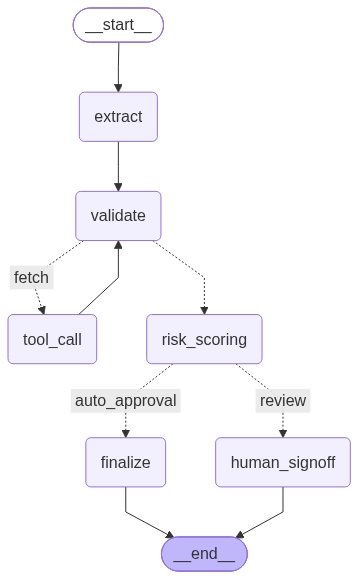

In [27]:
durable_graph = build_graph(checkpointer=saver)
dcfg = {"configurable": {"thread_id": THREAD_ID}}

show_graph(durable_graph, "UnderWriting LangGraph Workflow")

In [28]:
# Invoke the workflow
report = durable_graph.invoke(seed_report, dcfg)
print("Current State:", durable_graph.get_state(dcfg).next)

Current State: ('human_signoff',)


In [29]:
result = durable_graph.invoke(Command(resume={"action": "Human signoff done!"}), dcfg)

In [30]:
keys_to_extract = [
    'proposed_annual_debt_service_inr',
    'dscr',
    'sector_dscr_floor',
    'meets_dscr_floor',
    'leverage_ratio',
    'current_ratio',
    'revenue_variance_pct',
    'internal_grade',
    'indicative_rate_pct',
    'reason_codes',
    'risk_band',
    'approval_authority',
    'auto_approve_allowed',
    'requires_human_signoff',
    'log',
    'final_status'
    ]

# Dictionary comprehension
final_report = {key: result[key] for key in keys_to_extract}
final_report

{'proposed_annual_debt_service_inr': 557460,
 'dscr': 3.65,
 'sector_dscr_floor': 1.35,
 'meets_dscr_floor': True,
 'leverage_ratio': 1.81,
 'current_ratio': 1.8,
 'revenue_variance_pct': 0.0,
 'internal_grade': 'C1',
 'indicative_rate_pct': 14.0,
 'reason_codes': 'APPROVED_STANDARD',
 'risk_band': 'approve',
 'approval_authority': 'Credit Committee',
 'auto_approve_allowed': False,
 'requires_human_signoff': True,
 'log': ['Extracted data from the raw intake record',
  'Validator: 7 fields are missing',
  "Tool call: loan_application_details with arg {'applicant_id': 'ASH-A-00076'}.",
  "Tool call: bureau_reports with arg {'applicant_id': 'ASH-A-00076'}.",
  "Tool call: sector_policies with arg {'sector_name': 'Auto Components'}.",
  'Validator: 0 fields are missing',
  'risk scoring: calculated critical metrics and the risk band',
  'Human signoff provided'],
 'final_status': 'approve: Human signoff done!'}